# Dong et al. 2020 — Prostate Cancer — Step 02: Manifold / Trajectory

Gate 1 was **GO** (one continuous, sample-integrated manifold). The signature geography read in 01 is the
reference **non-branching** pattern — Gast/pSom **co-vary** (r ≈ +0.9) and both **oppose Crest** — with no two
diverging arms. Topology must match the biology: a single collapsed axis is fit with the scFates **`curve`**
(not a branching `tree` — `04_test.md` Chen attempt 5). We derive the curve hyperparameters for this cell
count, root from the signatures' developmental order (Gast/pSom-high = origin, Crest = terminal), and
**render the fitted curve edges over the cells** to confirm it is fold-free (`04_test.md` Chen attempt 6).

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('loaded processed manifold:', adata.shape[0], 'malignant cells')

loaded processed manifold: 9698 malignant cells


In [3]:
# confirm topology from the embedding + smoothed signatures (biology decides curve vs tree)
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); _, s, _ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
print('-> Gast/pSom co-vary (r>0), both oppose Crest -> single collapsed axis -> NON-BRANCHING (curve).')

UMAP aspect ratio (major/minor std): 1.09
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.90
  Crest_sm vs Gast_sm: r = -0.39
  Crest_sm vs pSom_sm: r = -0.53
-> Gast/pSom co-vary (r>0), both oppose Crest -> single collapsed axis -> NON-BRANCHING (curve).


In [4]:
# fold-diagnostic helper: min node-node distance among nodes >=3 edges apart, / median edge length
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks

# derive Nodes for this cell count and confirm fold-freeness across a small scan (02_train.md C1/C2)
print('curve hyperparameter scan (Nodes scale with cell count; epg_lambda=0.3, epg_mu=100):')
for N in [15, 20, 30]:
    b = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(b, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(b)
    print(f'  Nodes={N}: tips={tips} forks={forks} fold-ratio={sa:.2f} (>1 = fold-free)')
NODES = 20
print(f'\nselected Nodes={NODES} (~1 node/485 cells; all scans give 2 tips / 0 forks / fold-free).')

curve hyperparameter scan (Nodes scale with cell count; epg_lambda=0.3, epg_mu=100):
  Nodes=15: tips=2 forks=0 fold-ratio=2.98 (>1 = fold-free)
  Nodes=20: tips=2 forks=0 fold-ratio=2.59 (>1 = fold-free)
  Nodes=30: tips=2 forks=0 fold-ratio=2.32 (>1 = fold-free)

selected Nodes=20 (~1 node/485 cells; all scans give 2 tips / 0 forks / fold-free).


In [5]:
# fit the curve at the derived parameters
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=NODES, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'fitted curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f}')
assert forks == 0 and sa > 1, 'topology check failed (expected fold-free linear curve)'

fitted curve: 2 tips, 0 forks | fold self-approach ratio = 2.59


In [6]:
# derive root from the signatures' developmental order (Gast/pSom-high tip = origin; Crest = late)
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = node', root, '(Gast/pSom-high, Crest-low developmental origin; NOT rooted at Crest or a cycling state)')

tip 0: Gast=+0.0206 pSom=+0.0711 Crest=-0.0190
tip 2: Gast=+0.0563 pSom=+0.1364 Crest=-0.0604
derived root = node 2 (Gast/pSom-high, Crest-low developmental origin; NOT rooted at Crest or a cycling state)


In [7]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sn in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, adata.obs[sn]); print(f'  {sn}: rho={rho:+.3f} p={p:.1e}')
print('-> Gast/pSom decrease and Crest increases along pseudotime: origin=Gast/pSom, terminus=Crest.')

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.581 p=0.0e+00
  pSom_sm: rho=-0.714 p=0.0e+00
  Crest_sm: rho=+0.794 p=0.0e+00
  cyc_score: rho=-0.237 p=3.6e-124
-> Gast/pSom decrease and Crest increases along pseudotime: origin=Gast/pSom, terminus=Crest.


In [8]:
# rename milestones by biology (root end vs terminal end)
ms = adata.obs['milestones'].astype(str)
end_by_t = adata.obs.groupby('milestones', observed=True)['t'].mean().sort_values()
lo_ms, hi_ms = str(end_by_t.index[0]), str(end_by_t.index[-1])
adata.obs['milestones'] = adata.obs['milestones'].astype(str).replace(
    {lo_ms: 'Gast/pSom origin', hi_ms: 'Neural-crest terminus'}).astype('category')
print('milestones:', adata.obs['milestones'].value_counts().to_dict())

milestones: {'Neural-crest terminus': 5149, 'Gast/pSom origin': 4549}


In [9]:
# continuity confirmed on an INDEPENDENT embedding (diffusion map), not the UMAP the curve was fit on
sc.tl.diffmap(adata, n_comps=15)
dc1 = adata.obsm['X_diffmap'][:,1]
print(f'continuity: corr(pseudotime, diffusion DC1) = {spearmanr(t, dc1)[0]:+.2f} on an independent embedding')
print('monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.')

continuity: corr(pseudotime, diffusion DC1) = -0.67 on an independent embedding
monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.


In [10]:
# orientation for house linear panels: reuse X_umap_lin from 01, verify vs pseudotime
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'][:,0] = -adata.obsm['X_umap_lin'][:,0]; r = -r
print(f'house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f} (low pt -> left)')

house orientation reused from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.85 (low pt -> left)


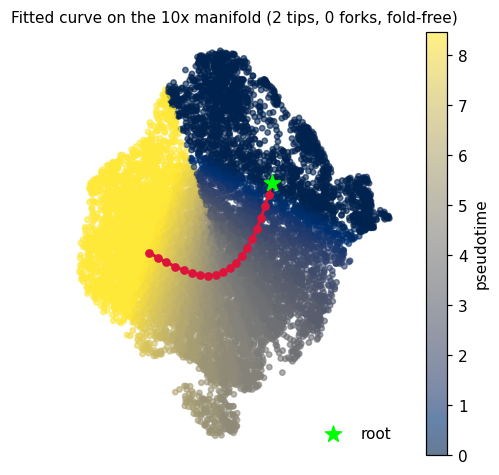

In [11]:
# render fitted curve edges over the cells (topology + fold-freeness visually verifiable) — full manifold
F = np.asarray(adata.uns['graph']['F']); Bc = np.asarray(adata.uns['graph']['B'])
ii, jj = np.where(np.triu(Bc>0))
fig, ax = plt.subplots(figsize=(5,5))
sca = ax.scatter(adata.obsm['X_umap'][:,0], adata.obsm['X_umap'][:,1], c=t, cmap='cividis', s=12, alpha=.6)
for a, b in zip(ii, jj):
    ax.plot([F[0,a],F[0,b]],[F[1,a],F[1,b]], '-', color='crimson', lw=2, zorder=5)
ax.scatter(F[0], F[1], c='crimson', s=22, zorder=6)
ax.scatter(*F[:,root], c='lime', s=120, marker='*', zorder=7, label='root')
ax.axis('off'); ax.legend(loc='lower right', frameon=False)
ax.set_title('Fitted curve on the 10x manifold (2 tips, 0 forks, fold-free)', size=10)
plt.colorbar(sca, ax=ax, label='pseudotime'); plt.show()

In [12]:
# sanitize non-serializable ElPiGraph uns entry, then save manifold.h5ad
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (9698, 15672)


saved manifold.pdf (curve edges rendered)


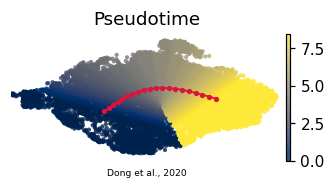

In [13]:
# manifold.pdf — house (3.5,1.5) linear strip, pseudotime on X_umap_lin, curve edges overlaid (deliverable)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
# map curve node positions into the SAME X_umap_lin frame as the cells
mu = np.asarray(adata.uns['lin_mean']); th = float(adata.uns['lin_rot'])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]])
Fc = (F.T - mu) @ Rm.T
cell_rot = (adata.obsm['X_umap'] - mu) @ Rm.T
flip = 1.0 if np.corrcoef(cell_rot[:,0], adata.obsm['X_umap_lin'][:,0])[0,1] > 0 else -1.0
Fc[:,0] = flip * Fc[:,0]
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
for a, b in zip(ii, jj):
    ax.plot([Fc[a,0],Fc[b,0]],[Fc[a,1],Fc[b,1]], '-', color='crimson', lw=1.2, zorder=5)
ax.scatter(Fc[:,0], Fc[:,1], c='crimson', s=6, zorder=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.pdf (curve edges rendered)')

**Manifold.** A single fold-free curve (**2 tips, 0 forks**, self-approach ratio ≫ 1) spans the malignant
manifold, rooted at the **Gast/pSom-high** developmental origin and running to the **neural-crest-high**
terminus. Pseudotime is monotonic against an independent diffusion component (continuity confirmed off the
embedding the curve was fit on). Non-branching linear geometry, consistent with the module geography — we
proceed to **03_signatures** (Gate 2).